# 05 · Optimización bayesiana, entrenamiento en alta calidad y test en EEG de pocos votos

**Fases CRISP-DM:** 4 – Modelado (iteración 2) y 5 – Evaluación

**Hipótesis del equipo:** los EEG anotados por pocos expertos (<10 votos) aportan poco al entrenamiento,
porque probablemente no contienen las señales más diferenciadoras (los expertos no logran distinguirlos
con claridad). Por lo tanto:
1. Se entrena **solo con EEG de alta calidad (≥10 votos)**.
2. Se optimizan los hiperparámetros de **dos arquitecturas** (EfficientNet-B0 y ConvNeXt-T, las mejores de
   la fase 1) con **optimización bayesiana** (Optuna, TPE multivariado, poda por mediana).
3. Se optimiza el **ensamble** de ambas (peso, tipo de promedio, temperatura).
4. Los EEG de **baja calidad (<10 votos) se usan solo como test**.

Además se audita si las métricas están **sesgadas por el desbalance de clases** (Other = 42 % de los EEG).

Código: `src/hq.py` (entrenamiento y optimización), `src/ensemble_opt.py` (ensamble y ajuste de priors),
`src/imbalance_audit.py` (auditoría), `run_hq.sh` (orquestación).

> **Nota de nomenclatura.** Este notebook pertenece a la **Iteración 2** de CRISP-DM. Las etiquetas internas
> (tablas, CSV y figuras) se generaron antes de ordenar el trabajo por iteraciones: **"fase 1"** = ciclo 2.1,
> **"iteración 2" / "Iter. 2"** = ciclo 2.2 e **"iteración 3"** = ciclo 2.3.


In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath("../.."))  # raíz del repo (notebooks/iteracion_2/ -> ../..)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from src.config import RESULTS_DIR, FIGURES_DIR, OOF_DIR, CACHE_DIR, TARGETS, CLASSES
from src.evaluate import balanced_metrics, kl_per_row
from src.viz import set_style, CLASS_COLORS, PALETTE, SEQ_CMAP
set_style()
pd.set_option("display.width", 220)
FIG = FIGURES_DIR / "optimizacion"; FIG.mkdir(exist_ok=True, parents=True)
OPT = RESULTS_DIR / "optuna"
meta = pd.read_csv(CACHE_DIR / "meta.csv")
hq = meta.total_votes >= 10

## 1. Protocolo y riesgo de fuga

Los EEG de alta y baja calidad **comparten pacientes**: entrenar con toda la alta calidad y evaluar en la baja
filtraría información del paciente. Por eso se mantienen los 5 folds agrupados por paciente de la fase 1:

| Modelo del fold *f* | Datos |
|---|---|
| Entrena con | EEG ≥10 votos de los folds ≠ *f* |
| Valida con | EEG ≥10 votos del fold *f* |
| **Test** | **EEG <10 votos del fold *f*** (pacientes nunca vistos, nunca usados para entrenar ni optimizar) |

La optimización bayesiana usa solo la validación de alta calidad del **fold 0**; por eso la CV de alta
calidad se reporta también **sin el fold 0** (`f1-4`). El test de baja calidad no participa en ninguna decisión.

In [2]:
ph, pl = set(meta[hq].patient_id), set(meta[~hq].patient_id)
print(f"EEG alta calidad: {hq.sum():,} ({len(ph)} pacientes) | baja calidad: {(~hq).sum():,} ({len(pl)} pacientes)")
print(f"Pacientes en ambos grupos: {len(ph & pl)} | EEG de baja calidad cuyo paciente tiene EEG de alta: "
      f"{meta[~hq].patient_id.isin(ph).sum():,} ({meta[~hq].patient_id.isin(ph).mean():.0%})")
dist = pd.crosstab(np.where(hq, ">=10 votos (train/valid)", "<10 votos (test)"), meta.expert_consensus,
                   normalize="index").reindex(columns=CLASSES) * 100
dist.round(1)

EEG alta calidad: 5,396 (960 pacientes) | baja calidad: 11,693 (1792 pacientes)
Pacientes en ambos grupos: 802 | EEG de baja calidad cuyo paciente tiene EEG de alta: 8,961 (77%)


expert_consensus,Seizure,LPD,GPD,LRDA,GRDA,Other
row_0,,,,,,
<10 votos (test),22.4,13.2,9.5,5.8,12.3,36.8
>=10 votos (train/valid),3.4,19.1,12.8,4.6,7.2,52.9


**Cambio de distribución:** el test tiene ~6.6× más *Seizure* (22 % vs. 3.4 %) y menos *Other*. Un modelo
entrenado solo con alta calidad aprende el prior de alta calidad, lo que penaliza la KL en el test aunque
el modelo distinga bien las clases. Para separar ambos efectos se reportan métricas insensibles al prior
(AUC, accuracy balanceada) y un ajuste de priors no supervisado (sección 6).

## 2. Auditoría: ¿las métricas están infladas por la clase mayoritaria?
Se comparan los modelos con dos referencias triviales —predecir siempre *Other* y predecir siempre la
distribución media— usando métricas donde cada clase pesa igual:
- **accuracy balanceada** (recall medio por clase), **F1 macro**, **kappa de Cohen** (0 = azar),
- **KL macro**: KL media calculada por clase de consenso y luego promediada,
- **recall mínimo** (peor clase) y **% de predicciones *Other*** frente al % real.

In [3]:
bal = pd.read_csv(RESULTS_DIR / "metrics_balance.csv")
cols = ["modelo", "subconjunto", "kl", "macro_kl", "accuracy", "balanced_accuracy", "macro_f1", "kappa",
        "macro_auc", "min_recall", "share_pred_other", "share_true_other"]
bal[bal.subconjunto == "todas"][cols].round(3)

,modelo,subconjunto,kl,macro_kl,accuracy,balanced_accuracy,macro_f1,kappa,macro_auc,min_recall,share_pred_other,share_true_other
0,Trivial: siempre Other,todas,2.474,3.339,0.419,0.167,0.098,0.000,0.500,0.000,1.000,0.419
1,Trivial: distribución media,todas,1.263,1.516,0.419,0.167,0.098,0.000,0.500,0.000,1.000,0.419
6,Gradient boosting (bandas),todas,0.882,1.062,0.569,0.438,0.467,0.380,0.835,0.115,0.603,0.419
9,EfficientNet-B0 (fase 1),todas,0.623,0.785,0.706,0.592,0.624,0.587,0.915,0.203,0.546,0.419
12,ConvNeXt-T (fase 1),todas,0.629,0.798,0.709,0.595,0.624,0.594,0.914,0.211,0.529,0.419
15,Ensamble 50/50 (fase 1),todas,0.576,0.732,0.717,0.599,0.633,0.602,0.923,0.201,0.548,0.419
18,EfficientNet-B0 sin optimizar,todas,0.814,1.014,0.642,0.495,0.525,0.476,0.886,0.160,0.651,0.419
21,EfficientNet-B0 optimizado,todas,0.729,0.885,0.664,0.536,0.567,0.518,0.898,0.213,0.604,0.419
24,ConvNeXt-T optimizado,todas,0.758,0.920,0.654,0.533,0.551,0.512,0.884,0.187,0.567,0.419
27,Ensamble optimizado,todas,0.701,0.837,0.668,0.538,0.567,0.523,0.901,0.196,0.604,0.419


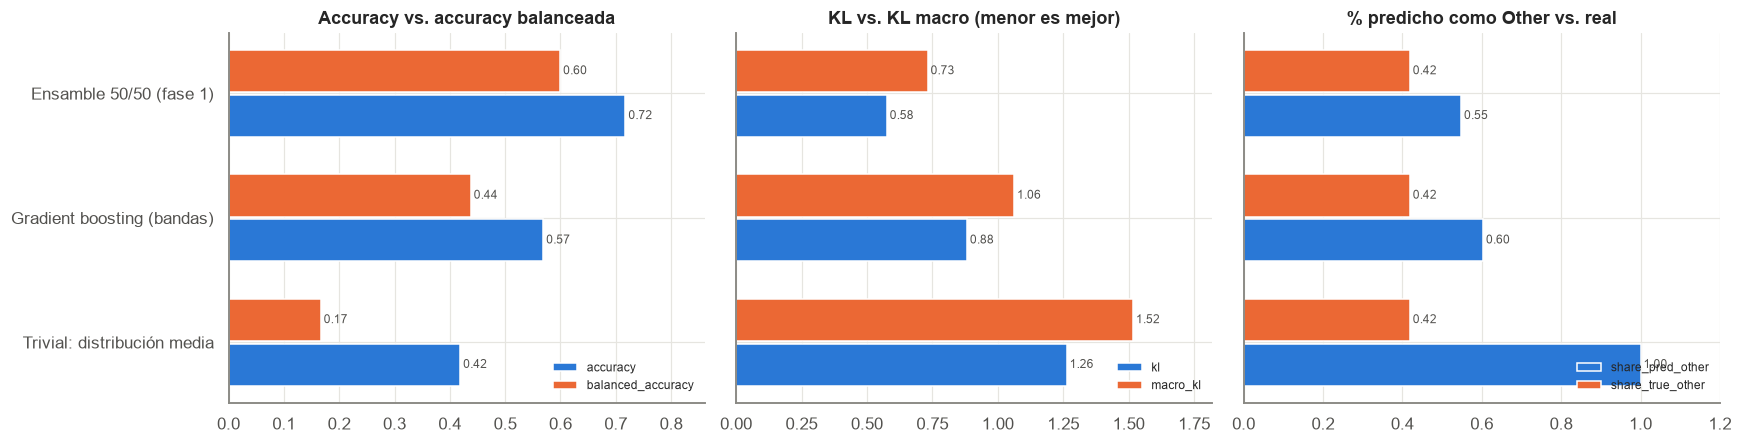

In [4]:
sub_order = ["todas", "alta calidad (>=10)", "baja calidad (<10)"]
show = ["Trivial: distribución media", "Gradient boosting (bandas)", "Ensamble 50/50 (fase 1)"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
pairs = [("accuracy", "balanced_accuracy", "Accuracy vs. accuracy balanceada"),
         ("kl", "macro_kl", "KL vs. KL macro (menor es mejor)"),
         ("share_pred_other", "share_true_other", "% predicho como Other vs. real")]
for ax, (a, b, t) in zip(axes, pairs):
    d = bal[(bal.subconjunto == "todas") & bal.modelo.isin(show)].set_index("modelo").loc[show]
    y = np.arange(len(d))
    ax.barh(y - 0.18, d[a], height=0.34, color=PALETTE[0], label=a)
    ax.barh(y + 0.18, d[b], height=0.34, color=PALETTE[1], label=b)
    for yy, va, vb in zip(y, d[a], d[b]):
        ax.text(va, yy - 0.18, f" {va:.2f}", va="center", fontsize=8, color="#52514e")
        ax.text(vb, yy + 0.18, f" {vb:.2f}", va="center", fontsize=8, color="#52514e")
    ax.set_yticks(y, d.index); ax.set_title(t); ax.legend(loc="lower right", fontsize=8); ax.margins(x=0.2)
fig.tight_layout(); fig.savefig(FIG / "auditoria_desbalance.png"); plt.show()

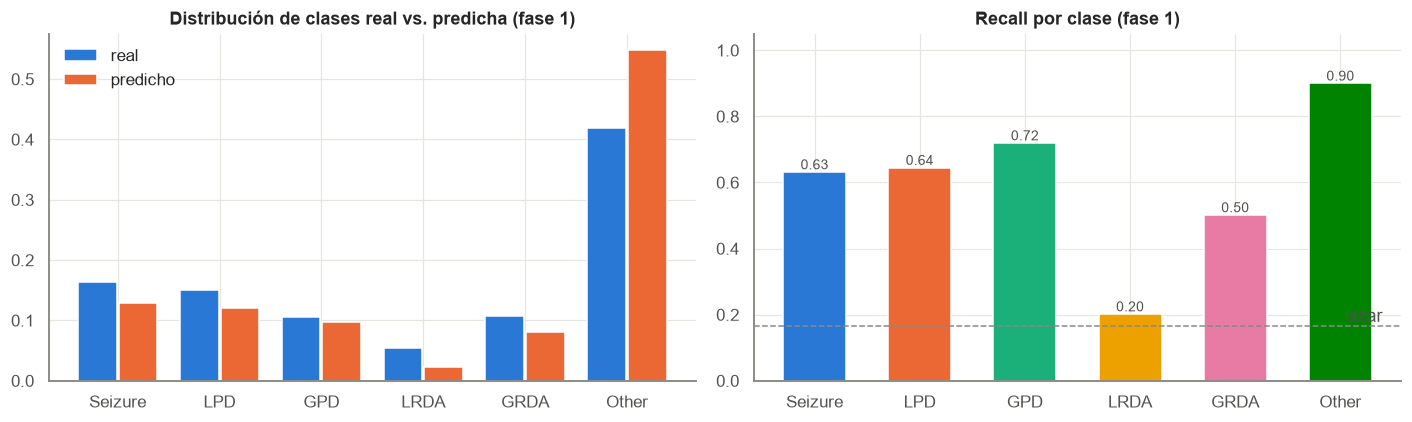

In [5]:
pc = pd.read_csv(RESULTS_DIR / "metrics_balance_por_clase.csv")
d = pc[(pc.modelo == "Ensamble 50/50 (fase 1)") & (pc.subconjunto == "todas")].set_index("clase").loc[CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(CLASSES))
axes[0].bar(x - 0.2, d.share_real, 0.38, color=PALETTE[0], label="real")
axes[0].bar(x + 0.2, d.share_predicha, 0.38, color=PALETTE[1], label="predicho")
axes[0].set_xticks(x, CLASSES); axes[0].set_title("Distribución de clases real vs. predicha (fase 1)"); axes[0].legend()
axes[1].bar(x, d.recall, 0.6, color=[CLASS_COLORS[c] for c in CLASSES])
for i, v in enumerate(d.recall): axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color="#52514e")
axes[1].axhline(1 / 6, color="#8a8984", ls="--", lw=1); axes[1].text(5.4, 1 / 6, "azar", color="#52514e", va="bottom", ha="right")
axes[1].set_xticks(x, CLASSES); axes[1].set_title("Recall por clase (fase 1)"); axes[1].set_ylim(0, 1.05)
fig.tight_layout(); fig.savefig(FIG / "recall_por_clase_fase1.png"); plt.show()

**Conclusión de la auditoría (fase 1):** sí hay sesgo hacia *Other*, pero los modelos no son triviales.
- La accuracy y la KL simple están **infladas por la clase mayoritaria**: en el ensamble de la fase 1 la
  accuracy cae de 0.717 a **0.599 balanceada** y la KL sube de 0.576 a **0.732 macro**. El modelo predice
  *Other* en el 55 % de los casos cuando solo el 42 % lo son.
- Aun así está muy lejos de las referencias triviales: kappa **0.60** (0 = azar), accuracy balanceada
  3.6× la del trivial (0.167) y AUC macro 0.92, que no depende de la frecuencia de las clases.
- La debilidad real está en las clases poco frecuentes: LRDA (recall 0.20) y GRDA (0.50).
- Consecuencia para esta fase: la optimización usa la **KL macro** como objetivo y se reportan siempre
  métricas balanceadas junto a la KL oficial.

## 3. Optimización bayesiana de hiperparámetros

Espacio de búsqueda (por arquitectura): learning rate (log), weight decay (log), épocas (6–20), tamaño de lote
(16/32), dropout, drop-path, calentamiento, probabilidad de intercambio de hemisferios, número y tamaño de las
máscaras tiempo/frecuencia, mixup (sobre imagen y distribución de votos) y **ponderación de clases** en la
pérdida (peso ∝ (1/frecuencia)^α, α ∈ [0, 1]).

**Objetivo: KL macro** en la validación de alta calidad del fold 0 (no la KL simple, que premia apoyarse en
*Other* — ver sección 2). El primer intento es la configuración de la fase 1. La poda compara intentos en la
misma fracción de su calendario de entrenamiento, para no penalizar a los entrenamientos largos.

In [6]:
studies = {}
for arch in ["effb0", "convnext_t"]:
    f = OPT / f"{arch}_trials.csv"
    if f.exists():
        t = pd.read_csv(f)
        studies[arch] = t
        b = json.load(open(OPT / f"{arch}_best.json"))
        print(f"{arch}: {len(t)} intentos | completos {(t.state == 'COMPLETE').sum()} | podados "
              f"{(t.state == 'PRUNED').sum()} | intento 0 (config. fase 1) = {t.value.iloc[0]:.4f} | "
              f"mejor = {b['value']:.4f} (intento {b['trial']})")

effb0: 30 intentos | completos 21 | podados 9 | intento 0 (config. fase 1) = 0.4911 | mejor = 0.4195 (intento 22)
convnext_t: 20 intentos | completos 11 | podados 9 | intento 0 (config. fase 1) = 0.5198 | mejor = 0.4780 (intento 9)


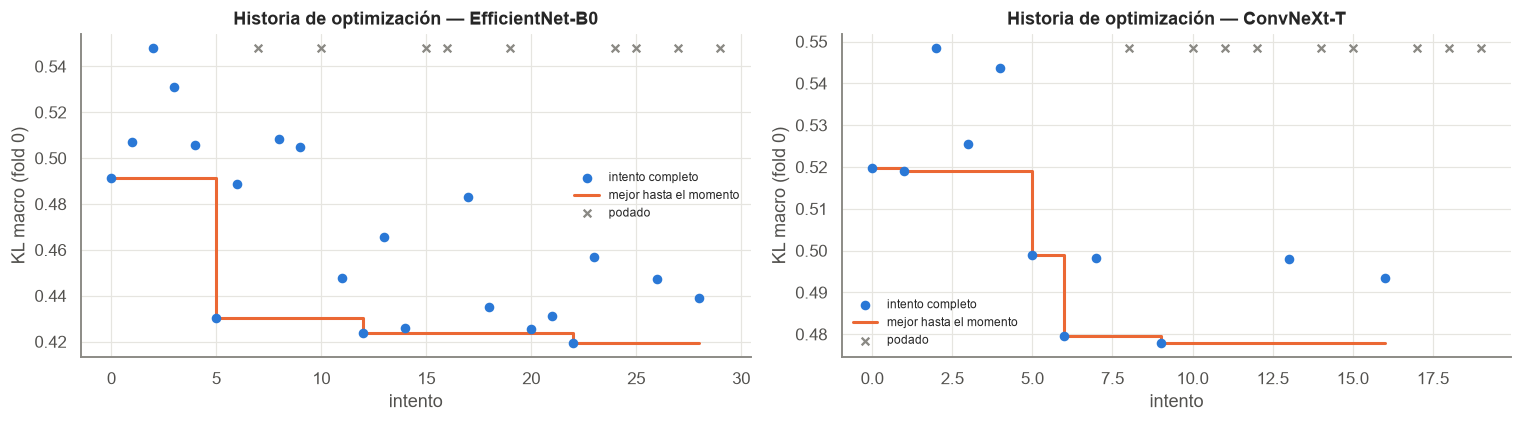

In [7]:
names = {"effb0": "EfficientNet-B0", "convnext_t": "ConvNeXt-T"}
fig, axes = plt.subplots(1, len(studies), figsize=(7 * len(studies), 4), squeeze=False)
for ax, (arch, t) in zip(axes[0], studies.items()):
    c = t[t.state == "COMPLETE"]
    ax.scatter(c.number, c.value, s=28, color=PALETTE[0], label="intento completo", zorder=3)
    ax.plot(c.number, c.value.cummin(), color=PALETTE[1], lw=2, drawstyle="steps-post", label="mejor hasta el momento")
    pr = t[t.state == "PRUNED"]
    ax.scatter(pr.number, [c.value.max()] * len(pr), marker="x", s=25, color="#8a8984", label="podado")
    ax.set_title(f"Historia de optimización — {names[arch]}"); ax.set_xlabel("intento"); ax.set_ylabel("KL macro (fold 0)")
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "historia_optuna.png"); plt.show()

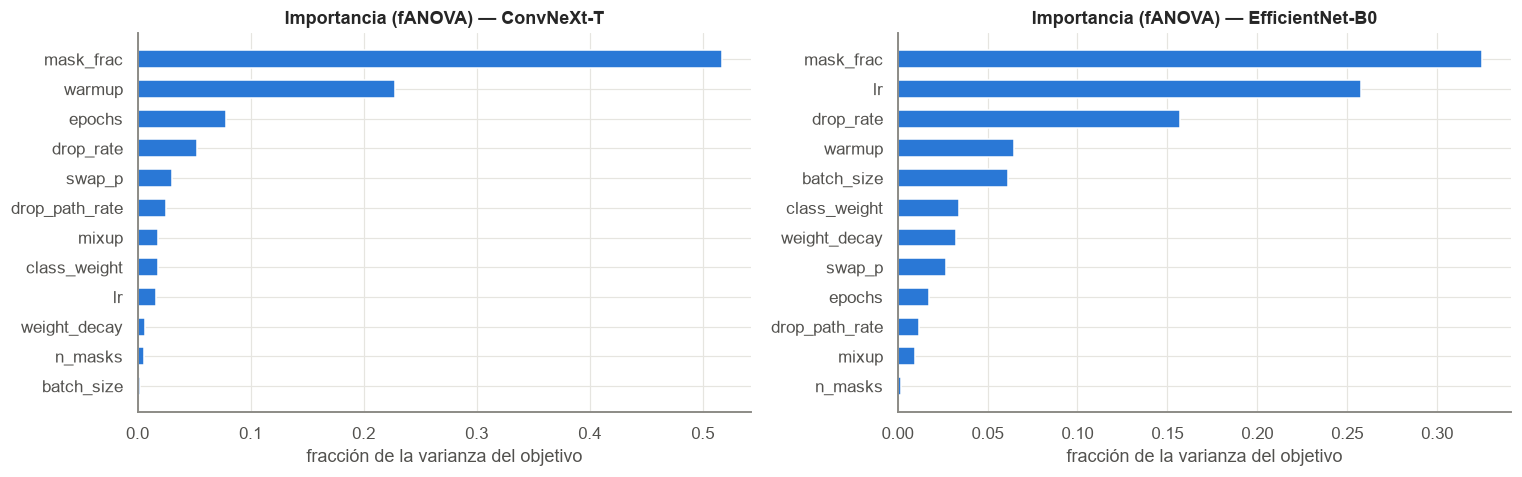

In [8]:
import optuna
rows = []
for arch in studies:
    st = optuna.load_study(study_name=arch, storage=f"sqlite:///{(OPT / f'{arch}.db').as_posix()}")
    imp = optuna.importance.get_param_importances(st, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=0))
    for k, v in imp.items():
        rows.append({"arquitectura": names[arch], "hiperparámetro": k, "importancia": v})
imp = pd.DataFrame(rows)
fig, axes = plt.subplots(1, len(studies), figsize=(7 * len(studies), 4.5), squeeze=False)
for ax, (a, g) in zip(axes[0], imp.groupby("arquitectura")):
    g = g.sort_values("importancia")
    ax.barh(g["hiperparámetro"], g.importancia, color=PALETTE[0], height=0.6)
    ax.set_title(f"Importancia (fANOVA) — {a}"); ax.set_xlabel("fracción de la varianza del objetivo")
fig.tight_layout(); fig.savefig(FIG / "importancia_hiperparametros.png"); plt.show()

In [9]:
best = {}
for arch in studies:
    b = json.load(open(OPT / f"{arch}_best.json"))
    best[names[arch]] = b["params"]
from src.hq import DEFAULTS
tbl = pd.DataFrame(best)
tbl.insert(0, "fase 1 (B0)", pd.Series(DEFAULTS["effb0"]))
tbl.insert(1, "fase 1 (ConvNeXt)", pd.Series(DEFAULTS["convnext_t"]))
tbl

,fase 1 (B0),fase 1 (ConvNeXt),EfficientNet-B0,ConvNeXt-T
lr,0.001,0.0002,0.001504,0.000112
weight_decay,0.010,0.0100,0.007716,0.001952
epochs,12.000,12.0000,8.000000,14.000000
batch_size,32.000,32.0000,16.000000,32.000000
drop_rate,0.200,0.2000,0.150305,0.392810
drop_path_rate,0.000,0.0000,0.137636,0.002954
warmup,0.100,0.1000,0.011497,0.007001
swap_p,0.500,0.5000,0.327666,0.477326
n_masks,2.000,2.0000,1.000000,3.000000
mask_frac,0.125,0.1250,0.227002,0.207182


**Lectura de la optimización (fold 0, KL macro):**
- **EfficientNet-B0:** 0.491 (configuración de la fase 1) → **0.420** (−15 %) en 30 intentos (9 podados).
  Prefiere learning rate alto (1.5e-3), **solo 8 épocas**, lote 16, mixup moderado (0.17), drop-path 0.14 y
  ponderación de clases leve (α = 0.12).
- **ConvNeXt-T:** 0.520 → **0.478** (−8 %) en 20 intentos (9 podados). Prefiere lr bajo (1.1e-4), mucha
  regularización (dropout 0.39), aumentos agresivos (3 máscaras de hasta 21 %) y **ponderación de clases fuerte (α = 0.84)**.
- **Importancia (fANOVA):** en ambas el hiperparámetro más influyente es el **tamaño de las máscaras de
  aumento** (52 % de la varianza del objetivo en ConvNeXt-T, 32 % en B0), seguido del calentamiento (ConvNeXt)
  y del learning rate y dropout (B0). Con 20–30 intentos estas importancias son aproximadas.
- Ambas configuraciones ganadoras regularizan más que la fase 1, coherente con el sobreajuste observado
  (solo ~4 300 EEG de entrenamiento).

## 4. Validación cruzada con los mejores hiperparámetros

In [10]:
mh = pd.read_csv(RESULTS_DIR / "metrics_hq.csv")
c = ["experiment", "minutes", "valid_hq_kl", "valid_hq_macro_kl", "valid_hq_f1-4_kl", "valid_hq_f1-4_macro_kl",
     "valid_hq_balanced_accuracy", "valid_hq_macro_auc",
     "test_lq_kl", "test_lq_macro_kl", "test_lq_balanced_accuracy", "test_lq_macro_auc"]
mh[[x for x in c if x in mh]].round(4)

,experiment,minutes,valid_hq_kl,valid_hq_macro_kl,valid_hq_f1-4_kl,valid_hq_f1-4_macro_kl,valid_hq_balanced_accuracy,valid_hq_macro_auc,test_lq_kl,test_lq_macro_kl,test_lq_balanced_accuracy,test_lq_macro_auc
0,hq_effb0_default,21.6,0.3773,NaN,0.3833,NaN,NaN,0.9128,1.0154,NaN,NaN,0.8836
1,hq_effb0,15.5,0.3465,0.4428,0.3537,0.447,0.5469,0.9194,0.9056,0.9964,0.5382,0.8972
2,hq_convnext_t,38.9,0.3864,0.4752,0.3961,0.478,0.5451,0.9062,0.9297,1.0326,0.5366,0.8828


## 5. Ensamble optimizado
Parámetros optimizados con Optuna (objetivo KL macro): peso de EfficientNet-B0 *w*, tipo de promedio
(aritmético de probabilidades / geométrico de log-probabilidades) y temperatura *T*.
Para la cifra honesta, los parámetros que se aplican a cada fold se eligen con los otros 4 folds (anidado).

In [11]:
eb = json.load(open(OPT / "ensemble_best.json"))
display(pd.DataFrame(eb["por_fold"]).round(4))
print("Parámetros finales (todas las predicciones de alta calidad, para despliegue):", eb["params"])

,fold,w,modo,T,kl_opt_otros_folds
0,0.0,0.6630,arit,1.1700,0.4146
1,1.0,0.6506,arit,1.1805,0.4164
2,2.0,0.6770,arit,1.1727,0.4184
3,3.0,0.6660,arit,1.1176,0.4085
4,4.0,0.6771,arit,1.1596,0.4012


Parámetros finales (todas las predicciones de alta calidad, para despliegue): {'w': 0.6461659465899031, 'modo': 'arit', 'T': 1.1661311597755868}


## 6. Resultados: validación de alta calidad y test de baja calidad

In [12]:
comp = pd.read_csv(RESULTS_DIR / "metrics_hq_comparacion.csv")
c = ["modelo", "entrenado_con", "valid_hq_kl", "valid_hq_macro_kl", "valid_hq_balanced_accuracy", "valid_hq_kappa",
     "valid_hq_macro_auc", "test_lq_kl", "test_lq_macro_kl", "test_lq_balanced_accuracy", "test_lq_kappa",
     "test_lq_macro_auc"]
comp[c].round(4)

,modelo,entrenado_con,valid_hq_kl,valid_hq_macro_kl,valid_hq_balanced_accuracy,valid_hq_kappa,valid_hq_macro_auc,test_lq_kl,test_lq_macro_kl,test_lq_balanced_accuracy,test_lq_kappa,test_lq_macro_auc
0,EfficientNet-B0 (fase 1),todos (2 etapas),0.3846,0.4654,0.5811,0.5740,0.9210,0.7331,0.8822,0.5978,0.5863,0.9167
1,ConvNeXt-T (fase 1),todos (2 etapas),0.3987,0.4901,0.5834,0.5700,0.9177,0.7356,0.8973,0.6017,0.5976,0.9147
2,Ensamble 50/50 (fase 1),todos (2 etapas),0.3474,0.4227,0.5840,0.5880,0.9284,0.6811,0.8300,0.6057,0.6020,0.9248
3,EfficientNet-B0 sin optimizar,>=10 votos,0.3773,0.5138,0.5048,0.5594,0.9128,1.0154,1.1354,0.4970,0.4400,0.8835
4,EfficientNet-B0 optimizado,>=10 votos,0.3465,0.4428,0.5470,0.5792,0.9194,0.9056,0.9966,0.5382,0.4908,0.8972
5,ConvNeXt-T optimizado,>=10 votos,0.3864,0.4752,0.5452,0.5630,0.9063,0.9297,1.0327,0.5367,0.4887,0.8828
6,Ensamble 50/50,>=10 votos,0.3384,0.4226,0.5505,0.5884,0.9213,0.8790,0.9724,0.5373,0.4921,0.8991
7,Ensamble optimizado (anidado),>=10 votos,0.3420,0.4130,0.5487,0.5888,0.9219,0.8671,0.9502,0.5402,0.4940,0.9004
8,Ensamble optimizado + EM priors,>=10 votos,0.3420,0.4130,0.5487,0.5888,0.9219,2.3423,2.7603,0.4322,0.3485,0.8046
9,Ensamble optimizado + BBSE priors,>=10 votos,0.3420,0.4130,0.5487,0.5888,0.9219,1.3119,1.8238,0.3814,0.3549,0.8210


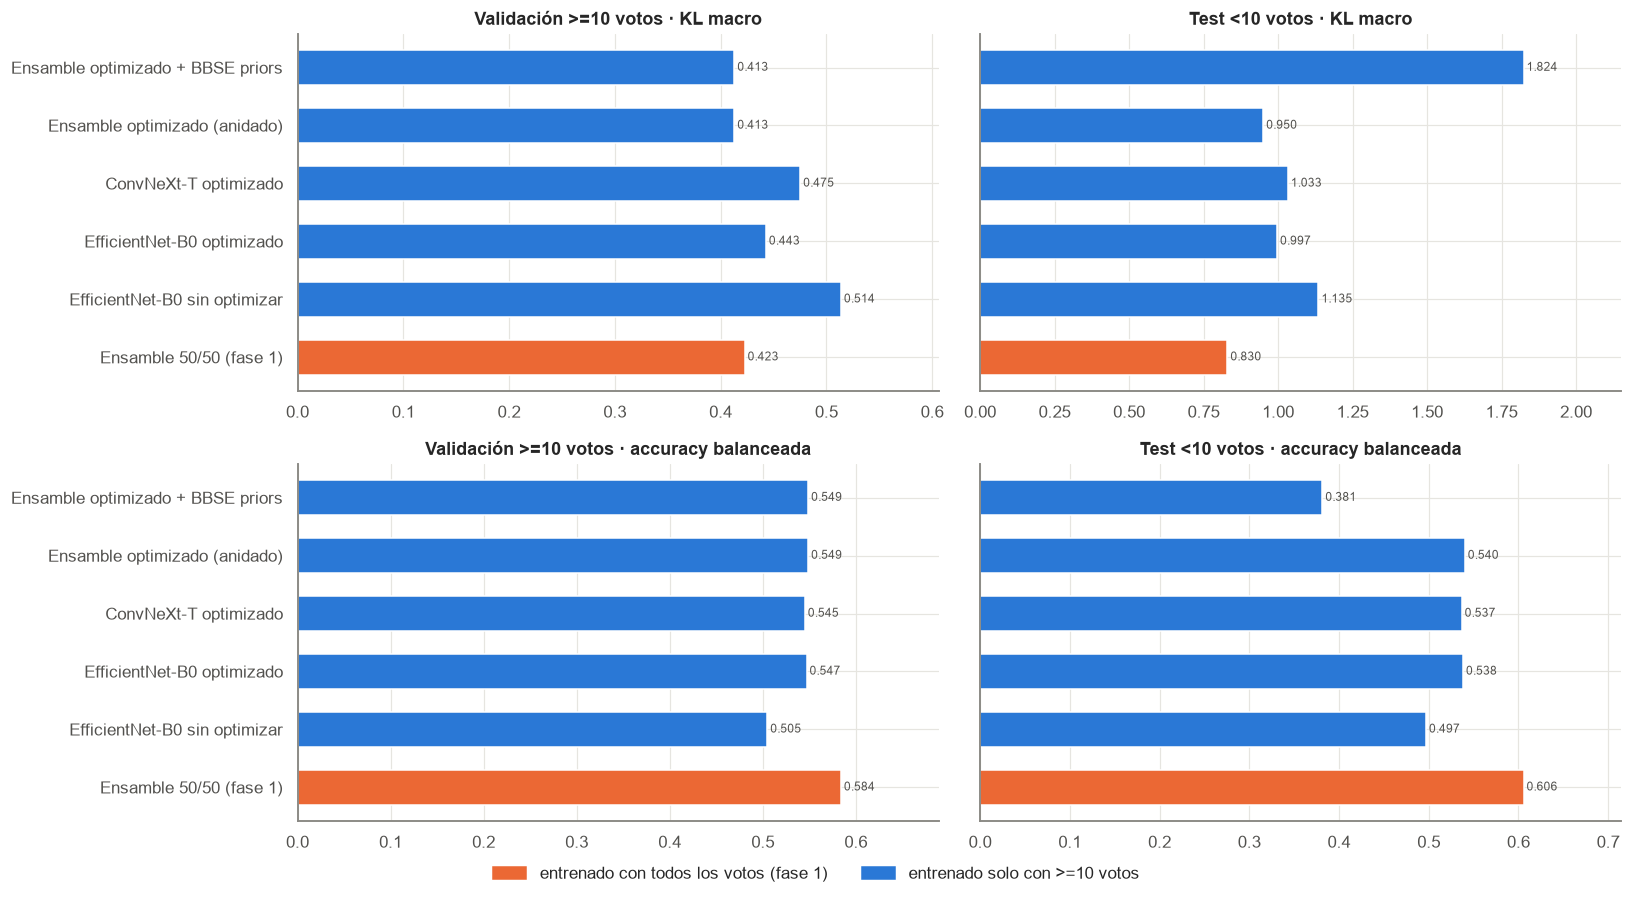

In [13]:
show = ["Ensamble 50/50 (fase 1)", "EfficientNet-B0 sin optimizar", "EfficientNet-B0 optimizado",
        "ConvNeXt-T optimizado", "Ensamble optimizado (anidado)", "Ensamble optimizado + BBSE priors"]
d = comp.set_index("modelo").loc[[s for s in show if s in set(comp.modelo)]]
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharey=True)
for ax, (col, t) in zip(axes.ravel(), [("valid_hq_macro_kl", "Validación >=10 votos · KL macro"),
                                        ("test_lq_macro_kl", "Test <10 votos · KL macro"),
                                        ("valid_hq_balanced_accuracy", "Validación >=10 votos · accuracy balanceada"),
                                        ("test_lq_balanced_accuracy", "Test <10 votos · accuracy balanceada")]):
    colors = [PALETTE[1] if "fase 1" in i else PALETTE[0] for i in d.index]
    ax.barh(d.index, d[col], color=colors, height=0.6)
    for y, v in enumerate(d[col]): ax.text(v, y, f" {v:.3f}", va="center", fontsize=8, color="#52514e")
    ax.set_title(t); ax.margins(x=0.18)
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[1]), plt.Rectangle((0, 0), 1, 1, color=PALETTE[0])]
fig.legend(handles, ["entrenado con todos los votos (fase 1)", "entrenado solo con >=10 votos"], loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(); fig.savefig(FIG / "comparacion_hq_lq.png"); plt.show()

### 6.1 ¿Cuánto del error en el test es cambio de prior?

,entrenamiento (>=10 votos),EM en test,BBSE en test,real del test (<10 votos)
Seizure,4.1,31.5,22.1,21.1
LPD,18.1,3.1,5.6,12.4
GPD,12.6,3.2,0.7,9.3
LRDA,7.0,26.1,10.6,6.2
GRDA,9.0,9.1,9.5,12.6
Other,49.2,27.0,51.4,38.4


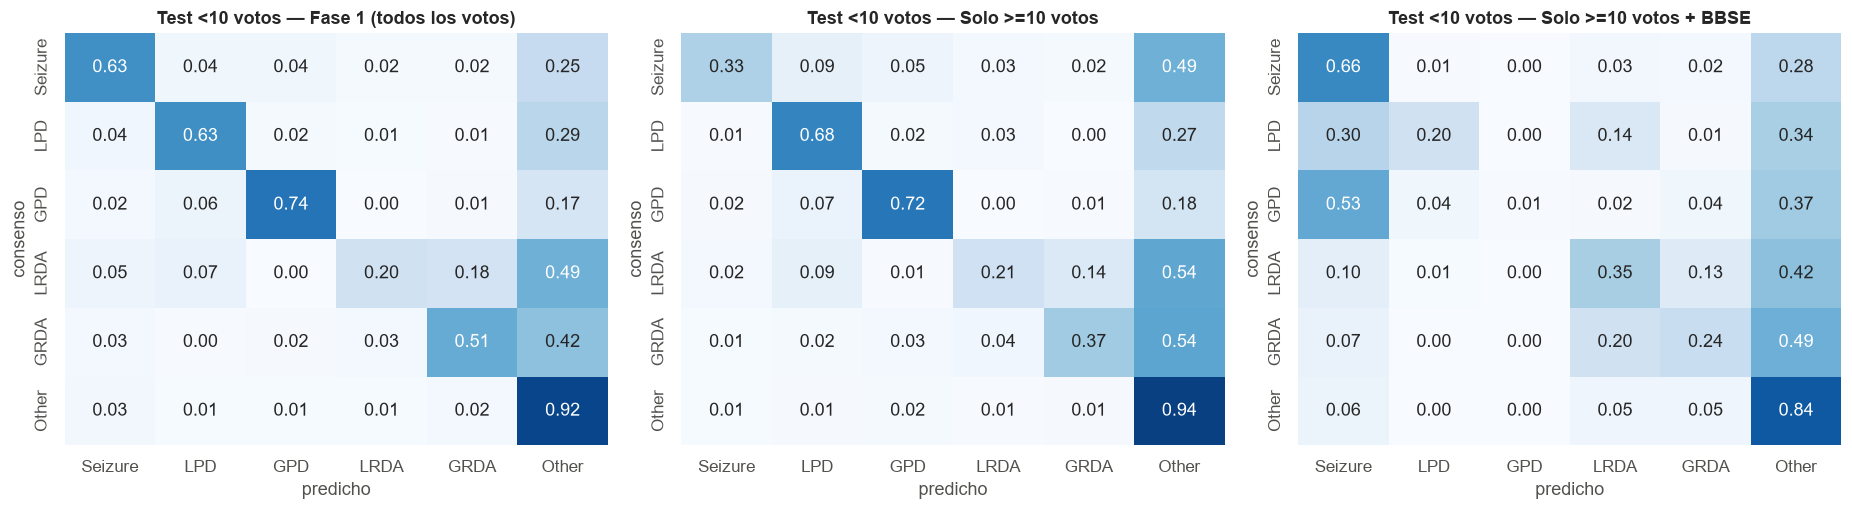

In [14]:
pri = pd.read_csv(OPT / "priors_test.csv", index_col=0)
pri.index = CLASSES
display((pri * 100).round(1))
oof_old = pd.read_csv(OOF_DIR / "ensemble.csv").set_index("eeg_id")
oof_new = pd.read_csv(OOF_DIR / "hq_ensemble.csv").set_index("eeg_id")
te = oof_new.split == "test_lq"
Y = oof_new.loc[te, TARGETS].to_numpy()
cands = {"Fase 1 (todos los votos)": oof_old.loc[oof_new.index[te], [f"pred_{t}" for t in TARGETS]].to_numpy(),
         "Solo >=10 votos": oof_new.loc[te, [f"pred_{t}" for t in TARGETS]].to_numpy(),
         "Solo >=10 votos + BBSE": oof_new.loc[te, [f"bbse_{t}" for t in TARGETS]].to_numpy()}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (n, P) in zip(axes, cands.items()):
    cm = confusion_matrix(Y.argmax(1), P.argmax(1), labels=range(6), normalize="true")
    sns.heatmap(pd.DataFrame(cm, CLASSES, CLASSES), annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(f"Test <10 votos — {n}"); ax.set_xlabel("predicho"); ax.set_ylabel("consenso")
fig.tight_layout(); fig.savefig(FIG / "confusion_test_lq.png"); plt.show()

### 6.2 ¿Los EEG de pocos votos son "más difíciles" para el modelo?
Si la hipótesis es cierta (no contienen las señales diferenciadoras), incluso un modelo entrenado con
ellos debería rendir peor en ellos. La AUC y la accuracy balanceada permiten comparar subconjuntos con
distinta distribución de clases.

In [15]:
rows = []
for n, f, col in [("Fase 1 (todos los votos)", "ensemble", "pred"), ("Solo >=10 votos (ensamble opt.)", "hq_ensemble", "pred")]:
    d = pd.read_csv(OOF_DIR / f"{f}.csv")
    for sub, m in [(">=10 votos", d.total_votes >= 10), ("<10 votos", d.total_votes < 10)]:
        Yd = d.loc[m, TARGETS].to_numpy(); Pd = d.loc[m, [f"{col}_{t}" for t in TARGETS]].to_numpy()
        b = balanced_metrics(Yd, Pd)
        rows.append({"modelo": n, "subconjunto": sub, **{k: b[k] for k in ["kl", "macro_kl", "balanced_accuracy", "kappa", "macro_auc"]}})
pd.DataFrame(rows).round(4)

,modelo,subconjunto,kl,macro_kl,balanced_accuracy,kappa,macro_auc
0,Fase 1 (todos los votos),>=10 votos,0.3474,0.4227,0.5840,0.5880,0.9284
1,Fase 1 (todos los votos),<10 votos,0.6811,0.8300,0.6057,0.6020,0.9248
2,Solo >=10 votos (ensamble opt.),>=10 votos,0.3420,0.4130,0.5487,0.5888,0.9219
3,Solo >=10 votos (ensamble opt.),<10 votos,0.8671,0.9502,0.5402,0.4940,0.9004


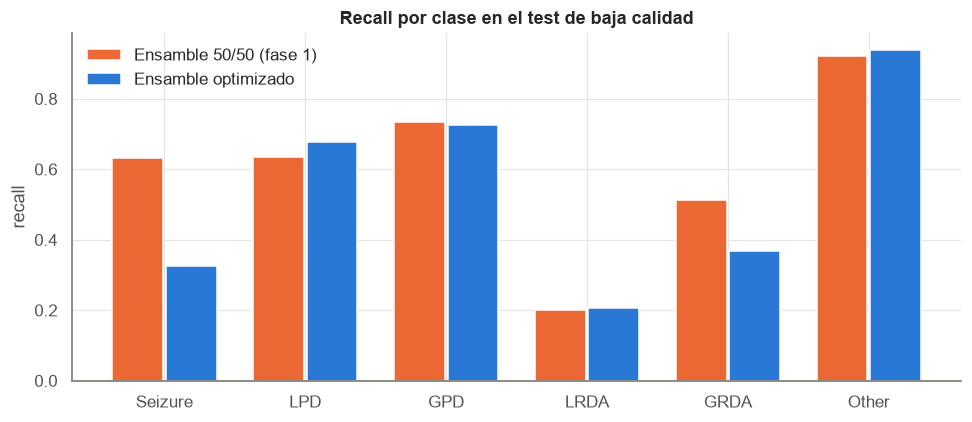

In [16]:
pcs = pc[pc.modelo.isin(["Ensamble 50/50 (fase 1)", "Ensamble optimizado"]) & (pc.subconjunto == "baja calidad (<10)")]
pv = pcs.pivot(index="clase", columns="modelo", values="recall").loc[CLASSES]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(CLASSES))
for i, (mname, color) in enumerate(zip(pv.columns, [PALETTE[1], PALETTE[0]])):
    ax.bar(x + (i - 0.5) * 0.38, pv[mname], 0.36, color=color, label=mname)
ax.set_xticks(x, CLASSES); ax.set_ylabel("recall"); ax.set_title("Recall por clase en el test de baja calidad"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "recall_test_lq.png"); plt.show()

## 7. Conclusiones

### Desempeño alcanzado (validación de alta calidad, 5 folds, pacientes no vistos)

| Modelo | KL | KL macro | Acc. balanceada | AUC |
|---|---|---|---|---|
| Ensamble fase 1 (todos los votos, sin optimizar) | 0.347 | 0.423 | **0.584** | **0.928** |
| EfficientNet-B0 optimizado (solo ≥10) | 0.347 | 0.443 | 0.547 | 0.919 |
| ConvNeXt-T optimizado (solo ≥10) | 0.386 | 0.475 | 0.545 | 0.906 |
| **Ensamble optimizado (solo ≥10, anidado)** | **0.342** | **0.413** | 0.549 | 0.922 |

- La optimización bayesiana funciona: un solo B0 optimizado iguala la KL del ensamble de dos modelos de la
  fase 1, y la mejora se mantiene sin el fold usado para optimizar (B0: 0.383 → 0.354 en folds 1–4).
- El ensamble optimizado (w ≈ 0.65 para B0, promedio aritmético, temperatura ≈ 1.17) es el mejor en **KL y
  KL macro** sobre alta calidad, pero no en accuracy balanceada ni AUC.

### Test en EEG de pocos votos (<10, nunca usados para entrenar ni optimizar)

| Modelo | KL | KL macro | Acc. balanceada | AUC |
|---|---|---|---|---|
| Ensamble fase 1 (vio datos de pocos votos de otros pacientes) | **0.681** | **0.830** | **0.606** | **0.925** |
| Ensamble optimizado solo ≥10 | 0.867 | 0.950 | 0.540 | 0.900 |
| … + prior real del test (oráculo) | 0.775 | 0.915 | 0.546 | 0.902 |
| … + prior estimado (BBSE / EM) | 1.312 / 2.342 | — | — | — |

### ¿Se sostiene la hipótesis?
**Parcialmente.**
1. **A favor:** para predecir sobre EEG de alta calidad, quitar los de pocos votos y optimizar no pierde KL
   (0.342 vs. 0.347) y mejora GPD y LPD. Además, los métodos de corrección de prior fallan en el test: estiman
   casi 0 % de GPD (real 9 %) y destruyen esas predicciones. Eso indica que **en los EEG de pocos votos cada
   clase "se ve" distinta**, no solo en otra proporción: un cambio condicional, coherente con la idea de que
   esas muestras no contienen las mismas señales.
2. **En contra:** el **93.5 % de los EEG de Seizure tienen <10 votos** (2 618 de 2 800). Entrenando solo con alta
   calidad el modelo ve 182 crisis, y el recall de *Seizure* cae de 0.62 a **0.45** en alta calidad (y de 0.63 a
   0.33 en el test); GRDA también cae (0.46 → 0.36). La accuracy balanceada y la AUC empeoran. Para la clase
   clínicamente más importante, los datos de pocos votos sí son valiosos.
3. **Confusión de efectos:** la fase 1 no estaba optimizada. Una comparación justa requiere aplicar la misma
   optimización entrenando con todos los votos (o ponderando por número de votos).

**Recomendación:** no descartar los EEG de pocos votos sino **ponderarlos** (por ejemplo, peso creciente con el
número de votos, o el esquema de 2 etapas de la fase 1) y optimizar ese peso como un hiperparámetro más.